## Data Preprocessing ##

In [727]:
import random
import pickle
from collections import Counter
from timeit import default_timer as timer

import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial import distance
import sklearn.metrics
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets

import sklearn.metrics
import sklearn.datasets
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets

### Reading the whole train and validation dataset with mean and std normalization ###

In [728]:
mean = (0.49139968, 0.48215827 ,0.44653124)
std = (0.24703233, 0.24348505, 0.26158768)

transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.RandomHorizontalFlip(),
    # transforms.RandomRotation(10),
    transforms.Normalize(mean, std),
    # transforms.Grayscale(),
    torch.flatten
])

train_size = 50000
test_size = 10000
train_dataset =  datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, batch_size=train_size, num_workers=2)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, shuffle=True, batch_size=test_size, num_workers=2)

Files already downloaded and verified
Files already downloaded and verified


In [729]:
images_train, labels_train = next(iter(train_loader))
images_test, labels_test = next(iter(test_loader))

In [730]:
images_train = images_train.numpy()
labels_train = labels_train.numpy()
images_test = images_test.numpy()
labels_test = labels_test.numpy()

### Cifar10 Classes ###

In [731]:
classes = ('airplane', 
           'auto', 
           'bird',
           'cat',
           'deer',
           'dog', 
           'frog', 
           'horse', 
           'ship',
           'truck')

### PCA keeping 90% of the variance ###

In [ ]:
pca = PCA(0.9)
pca.fit(images_train)

print(pca.n_components_)

train_pca = pca.transform(images_train)
test_pca = pca.transform(images_test)

Time:  13.400394600001164
99


# Classification using the Cifar10 Dataset #

## Different Classifiers ##

### Sklearn k-Nearest Neighbors for k = 1 ###

In [733]:
classifier_1NC = KNeighborsClassifier(n_neighbors=1)

classifier_1NC.fit(train_pca, labels_train)
predictions_1NC = classifier_1NC.predict(test_pca)

              precision    recall  f1-score   support

           0       0.45      0.51      0.47      1000
           1       0.59      0.32      0.41      1000
           2       0.27      0.40      0.33      1000
           3       0.31      0.24      0.27      1000
           4       0.28      0.44      0.34      1000
           5       0.39      0.30      0.34      1000
           6       0.33      0.44      0.38      1000
           7       0.54      0.36      0.43      1000
           8       0.45      0.58      0.50      1000
           9       0.58      0.28      0.38      1000

    accuracy                           0.39     10000
   macro avg       0.42      0.39      0.39     10000
weighted avg       0.42      0.39      0.39     10000



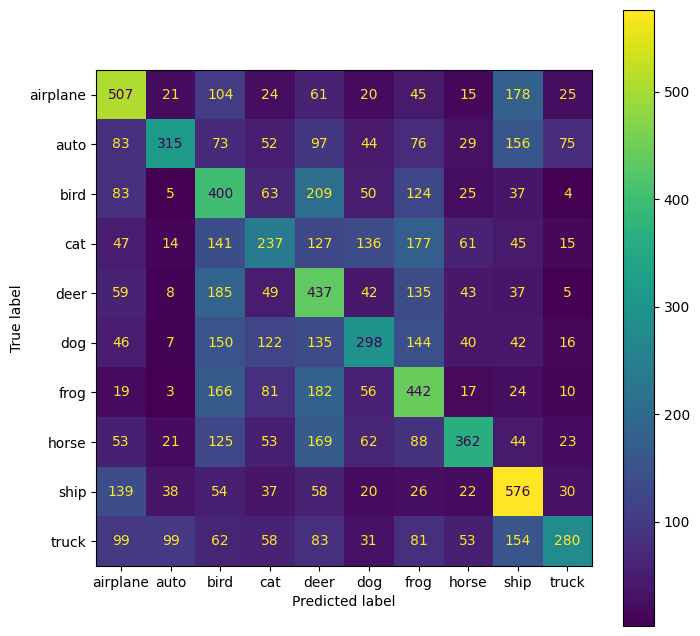

In [734]:
print(sklearn.metrics.classification_report(labels_test, predictions_1NC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_1NC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Sklearn k-Nearest Neighbors for k = 3 ###

In [735]:
classifier_3NC = KNeighborsClassifier(n_neighbors=3)

classifier_3NC.fit(train_pca, labels_train)
distances_3NC, indices_3NC = classifier_3NC.kneighbors(test_pca, n_neighbors=3, return_distance=True)
kneighbors_3NC = [labels_train[i] for i in indices_3NC]
predictions_3NC = [int(Counter(i).most_common(3)[0][0]) for i in kneighbors_3NC]

              precision    recall  f1-score   support

           0       0.46      0.52      0.49      1000
           1       0.64      0.30      0.41      1000
           2       0.27      0.39      0.32      1000
           3       0.31      0.22      0.26      1000
           4       0.28      0.46      0.35      1000
           5       0.41      0.29      0.34      1000
           6       0.33      0.45      0.38      1000
           7       0.55      0.35      0.43      1000
           8       0.44      0.63      0.51      1000
           9       0.61      0.28      0.38      1000

    accuracy                           0.39     10000
   macro avg       0.43      0.39      0.39     10000
weighted avg       0.43      0.39      0.39     10000



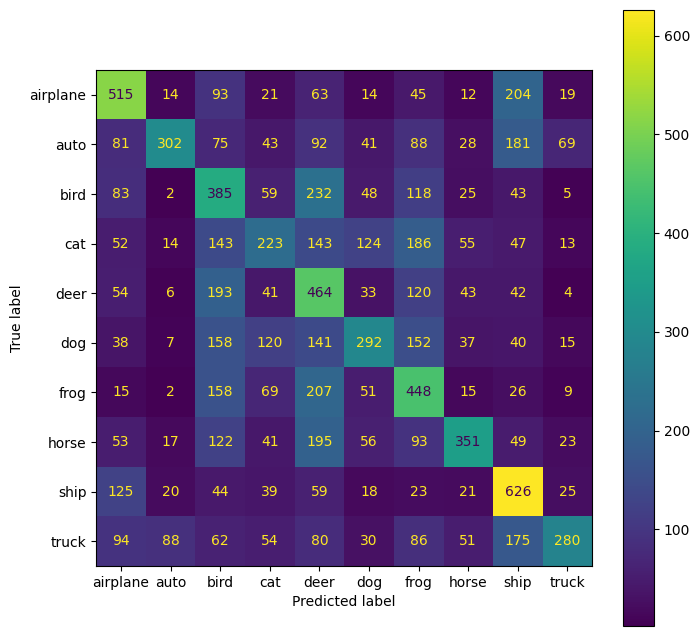

In [736]:
print(sklearn.metrics.classification_report(labels_test, predictions_3NC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_3NC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Sklearn Nearest Centroid ###

In [737]:
classifier_NC = NearestCentroid()

classifier_NC.fit(train_pca, labels_train)
predictions_NC = classifier_NC.predict(test_pca)

              precision    recall  f1-score   support

           0       0.27      0.53      0.35      1000
           1       0.27      0.18      0.22      1000
           2       0.29      0.11      0.16      1000
           3       0.27      0.06      0.09      1000
           4       0.28      0.12      0.17      1000
           5       0.27      0.29      0.28      1000
           6       0.22      0.53      0.31      1000
           7       0.26      0.17      0.20      1000
           8       0.42      0.37      0.39      1000
           9       0.33      0.41      0.36      1000

    accuracy                           0.28     10000
   macro avg       0.29      0.28      0.25     10000
weighted avg       0.29      0.28      0.25     10000



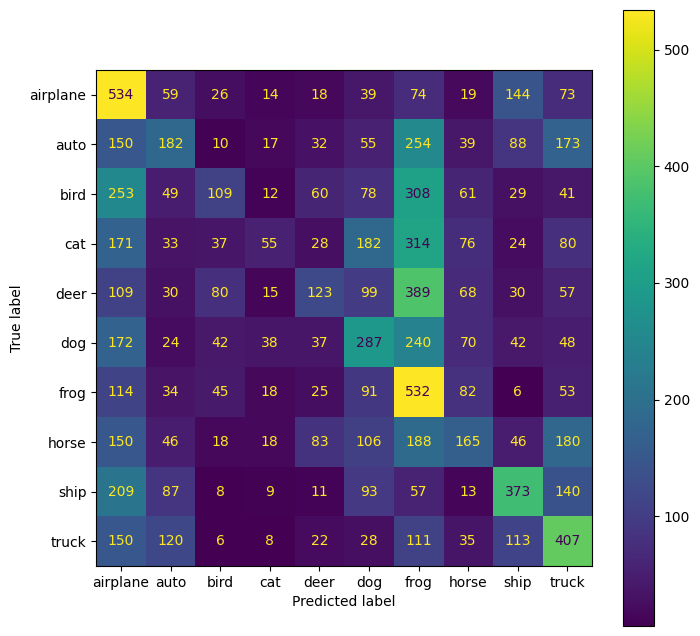

In [738]:
print(sklearn.metrics.classification_report(labels_test, predictions_NC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_NC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

## My Radial Basis Function Neural Network ##

#### Loss Functions and Derivatives ####

In [739]:
def MSE(y_true, y_pred):
    return np.mean(np.power(y_true - y_pred, 2))

def MSEprime(y_true, y_pred):
    return 2 * (np.sum(y_pred - y_true)) / np.size(y_true)

def CE(y_true, y_pred):
    loss = np.zeros(len(y_pred))
    for i, y in enumerate(y_pred):
        loss[i] = -y_true[i][y] + np.log(np.sum(np.exp(y_true[i]))) 
    return np.mean(loss)

def CEprime(y_true, y_pred):
    grad = np.zeros(y_true.shape)
    # t = np.zeros(y_true.shape)
    # t[np.arange(y_pred.size), y_pred] = 1
    for i, y in enumerate(y_true):
        for j, p in enumerate(y):
            grad[i][j] = np.exp(p)/np.sum(np.exp(y)) - y_pred[i][j]
    return np.sum(grad, axis = 0)

#### Radial Basis Functions ####

In [740]:
def gaussian(input, centers, std_dev):
    return np.array([np.exp(np.linalg.norm(input-c)**2 *(-1) / (2*std_dev**2)) for c in centers]).reshape(1, -1)

def multiquadric(input, centers, std_dev):
    return np.array([(np.linalg.norm(input-c)**2 + std_dev**2)**(1/2) for c in centers]).reshape(1, -1)

def cauchy(input, centers, std_dev):
    return np.array([np.exp(((np.linalg.norm(input-c)**2 + std_dev**2)**(-1) / std_dev)) for c in centers]).reshape(1, -1)

#### Layer template ####

In [741]:
class Layer():
    def __init__(self):
        self.input = None
        self.output = None
        self.grad = None
        
    def forward(self, input):
        # TODO: return output
        pass

    def backward(self, gradient):
        # TODO: update parameters and return input gradient
        pass

#### Dense Layer ####

In [742]:
class Dense(Layer):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.output_size=output_size
        self.weights = np.random.randn(output_size, input_size) * (np.sqrt(2 / input_size ))
        self.bias = np.zeros([output_size,1])
        
    def forward(self, input):
        if input.ndim == 1:
            input = input[:,np.newaxis]

        self.input = input.T
        result = np.matmul(self.weights, self.input) + self.bias
        return result
    
    def backward(self, gradient):
        if gradient.ndim == 1:
            gradient = gradient[:,np.newaxis]

        weights_gradient = np.matmul(gradient, self.input.T)
        input_gradient = np.matmul(self.weights.T, gradient)

        if len(gradient) > 0:
            self.grad = {"weights": weights_gradient, "bias": gradient} 
        
        return input_gradient


#### Radial Basis Function Layer ####

In [743]:
class RBF(Layer):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.num_centers = output_size
        self.centers = None
        self.function = "gaussian"

    def forward(self, input):
        if input.ndim == 1:
            input = input[:,np.newaxis]
        
        if self.function == "gaussian":
            a = gaussian(input, self.centers, self.std_dev)
        if self.function == "multiquadric":
            a = multiquadric(input, self.centers, self.std_dev)
        if self.function == "cauchy":
            a = cauchy(input, self.centers, self.std_dev)
        

        a = a.reshape(1, -1)
        self.input = input
        
        return a
    
    def backward(self, gradient):
        return gradient 

#### Stochastic Gradient Descent and Adagrad Optimizers ####

In [744]:
class SGD():
    def __init__(self, layers, lr = 0.01):
        self.lr = lr
        self.layers = layers

    def update(self):
        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                layer.weights -= self.lr * layer.grad["weights"]
                layer.bias -= self.lr * layer.grad["bias"]

class Adagrad():
    def __init__(self, layers, lr = 0.01, eps = 1e-10):
        self.lr = lr
        self.G = []
        self.layers = layers
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                self.G.append({"weights": np.zeros(layer.weights.shape), "bias": np.zeros(layer.bias.shape)})
            else:
                self.G.append({})
        self.eps = eps

    def update(self):
        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                # self.G[i] = {"weights": grads[i]['weights']**2, "bias": grads[i]['bias']**2} #np.concat((weights_gradient, gradient), axis = 1)
                self.G[i]["weights"] += layer.grad['weights']**2
                self.G[i]["bias"] += layer.grad['bias']**2
                
                layer.weights -= layer.grad["weights"]*self.lr/np.sqrt(self.G[i]["weights"] + self.eps)
                layer.bias -= layer.grad["bias"]*self.lr/np.sqrt(self.G[i]["bias"] + self.eps)

#### One Hot Encoding ####

In [745]:
def one_hot(y):
    if type(y) == torch.Tensor:
        y = y.numpy()
    y_train = np.zeros([y.size, 10])
    y_train[np.arange(y.size), y] = 1
    return y_train

#### Kmeans ####

In [746]:
def separate_classes(pca_train_data, y_train, num_classes=10):
    class_subsets = [pca_train_data[y_train == i] for i in range(num_classes)]
    return class_subsets

def apply_kmeans_to_classes(class_subsets, n_clusters, max_iters=100):
    kmeans_results = []
    for class_data in class_subsets:
        kmeans = KMeans(n_clusters=n_clusters, max_iter=max_iters, random_state=0, n_init='auto')
        kmeans.fit(class_data)
        kmeans_results.append((kmeans.cluster_centers_, kmeans.labels_))
    return kmeans_results

#### Radial Basis Function Neural Network ####

In [747]:
class MyRBFNN():
    
    def __init__(self, layers, name, optimizer, epochs = 50, lr = 0.01, std_dev=0.1, function="gaussian"):
        self.layers = layers
        self.name = name
        self.params = []
        self.epochs = epochs
        self.lr = lr
        self.layers[0].std_dev = std_dev 
        self.layers[0].function = function 
        
        if optimizer == 'SGD':
            self.optimizer = SGD(self.layers, self.lr)
        if optimizer == 'Adagrad':
            self.optimizer = Adagrad(self.layers, self.lr)

    def forward(self, input):
        for layer in self.layers:
            input = layer.forward(input)
        return input

    def backward(self, gradient):
        self.gradient = gradient
        for layer in reversed(self.layers):
            self.gradient = layer.backward(self.gradient)

    def update(self):
        self.optimizer.update()

    def predict(self, input):
        output = []
        for x in input:
            output.append(np.argmax(self.forward(x), axis = 0)[0])
        return np.array(output)
    
    def train(self, images_train, labels_train, images, labels, initialization, batch_size = 1, verbose = True):
        if initialization == 'random':
            idx = np.random.randint(images_train.shape[0], size=self.layers[0].num_centers)
            self.layers[0].centers = images_train[idx]
        if initialization == 'kmeans':
            class_subsets = separate_classes(images_train, labels_train)

            kmeans_results = apply_kmeans_to_classes(class_subsets, n_clusters=self.layers[0].num_centers//self.layers[-1].output_size)
            # Extracting and combining the centroids from kmeans_results
            self.layers[0].centers = np.vstack([centers for centers, _ in kmeans_results])   
                    
        train_acc = []
        val_acc = []
        for e in range(self.epochs):
            error = 0
            correct = 0
            best = 0
            for id_batch, x_batch in enumerate(images_train):
                x_batch = np.atleast_2d(x_batch)
                y_batch = labels_train[id_batch]
                y_batch = np.atleast_2d(y_batch)
                
                y_train = one_hot(y_batch)
                output = self.forward(x_batch).T
                
                output -= np.max(output) #Prevents nan values in exp. The correct way to do this is batch normalization
                preds = np.argmax(output, axis = 1)

                correct += (np.argmax(output, axis = 1) == y_batch).sum()

                error += CE(y_train, preds) #Cross Entropy
                new_grad = CEprime(output, y_train) #Derivative of Cross Entropy
                #Backpropagation

                self.backward(new_grad)
                
                self.update()
                
            error /= len(images_train)
            accuracy = float(correct) / len(images_train)

            self.save_model(str(e))
            if accuracy > best:
                best = accuracy
                self.save_model("best")

            if verbose:
                predictions = []
                for x in images:
                    pred = int(np.argmax(self.forward(np.atleast_2d(x))))
                    predictions.append(pred)
                val = float(np.sum(predictions == labels)) / len(labels)
                val_acc.append(val)
                train_acc.append(accuracy)

                print(f"{e + 1}/{self.epochs}, error={error}, train accuracy={accuracy}, validation accuracy={val}")
        if verbose:
            plt.plot(np.arange(self.epochs), train_acc, label='Training Accuracy')
            plt.plot(np.arange(self.epochs), val_acc, label='Validation Accuracy')
            plt.legend()
            plt.show()

    def save_model(self, epoch):
        weights = []
        bias = []
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                weights.append(layer.weights)
                bias.append(layer.bias)
            else:
                weights.append([])
                bias.append([])
        
        dbfile = open('models/'+ self.name + 'weights_e'+ epoch, 'ab')
        pickle.dump(weights, dbfile)                    
        dbfile.close()

        dbfile = open('models/'+ self.name + 'bias_e'+ epoch, 'ab')
        pickle.dump(bias, dbfile)                    
        dbfile.close()

        dbfile = open('models/'+ self.name + 'centers_e'+ epoch, 'ab')
        pickle.dump(self.layers[0].centers, dbfile)                    
        dbfile.close()


    def load_model(self, name, epoch):
        dbfile = open('models/'+ name + 'weights_e'+ epoch, 'rb')    
        weights = pickle.load(dbfile)
        dbfile.close()

        dbfile = open('models/'+ name + 'bias_e'+ epoch, 'rb')    
        bias = pickle.load(dbfile)
        dbfile.close()

        dbfile = open('models/'+ name + 'centers_e'+ epoch, 'rb')    
        self.layers[0].centers = pickle.load(dbfile)
        dbfile.close()

        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                layer.weights = weights[i]
                layer.bias = bias[i]

## RBF NN runs ##

### Parameteres used (Gaussian Models use double the epochs) ###

In [ ]:
epochs = 50
std_dev = 50
lr = 0.01
num_centers = 500

### Multiquadric Radial Basis Function with Adagrad Optimizer and K-Means Center Initialization ###

1/50, error=2.281950171733157, train accuracy=0.1792, validation accuracy=0.1823
2/50, error=2.254850171733204, train accuracy=0.2063, validation accuracy=0.1967
3/50, error=2.2428301717332224, train accuracy=0.21832, validation accuracy=0.2027
4/50, error=2.235490171733232, train accuracy=0.22566, validation accuracy=0.2056
5/50, error=2.2300901717332384, train accuracy=0.23106, validation accuracy=0.2109
6/50, error=2.225470171733247, train accuracy=0.23568, validation accuracy=0.2152
7/50, error=2.2201101717332543, train accuracy=0.24104, validation accuracy=0.2171
8/50, error=2.2165901717332597, train accuracy=0.24456, validation accuracy=0.221
9/50, error=2.2127301717332655, train accuracy=0.24842, validation accuracy=0.2254
10/50, error=2.20961017173327, train accuracy=0.25154, validation accuracy=0.2293
11/50, error=2.207050171733275, train accuracy=0.2541, validation accuracy=0.2333
12/50, error=2.204770171733279, train accuracy=0.25638, validation accuracy=0.2356
13/50, error=

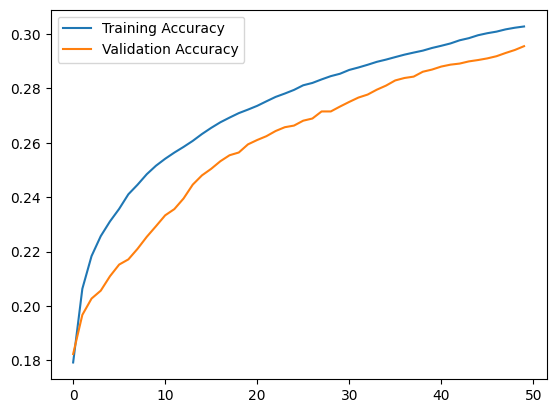

In [ ]:
layers = [ 
    RBF(images_train.shape[1], num_centers),
    Dense(num_centers, 10)
]
quad = MyRBFNN(layers, 'quad', 'Adagrad', epochs, lr, std_dev, 'multiquadric')

quad.train(train_pca, labels_train, test_pca, labels_test, 'kmeans', batch_size=train_size, verbose=True)

              precision    recall  f1-score   support

           0       0.33      0.62      0.43      1000
           1       0.35      0.51      0.42      1000
           2       0.57      0.00      0.01      1000
           3       0.24      0.08      0.12      1000
           4       0.24      0.53      0.33      1000
           5       0.45      0.23      0.30      1000
           6       0.43      0.28      0.34      1000
           7       0.21      0.57      0.30      1000
           8       0.59      0.06      0.12      1000
           9       0.57      0.08      0.14      1000

    accuracy                           0.30     10000
   macro avg       0.40      0.30      0.25     10000
weighted avg       0.40      0.30      0.25     10000



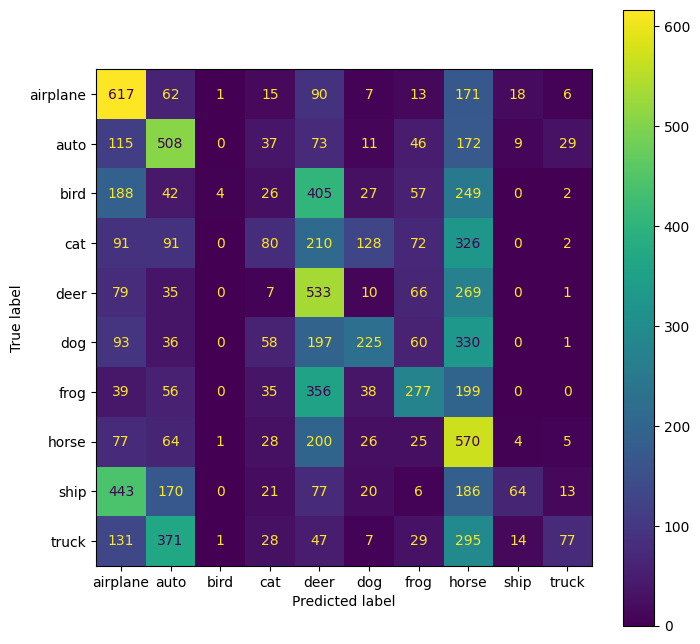

In [774]:
predictions_quad = []
for x in test_pca:
    pred = int(np.argmax(quad.forward(np.atleast_2d(x))))
    predictions_quad.append(pred)

print(sklearn.metrics.classification_report(labels_test, predictions_quad))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_quad)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Cauchy Radial Basis Function with Adagrad Optimizer and K-Means Center Initialization ###

In [824]:
layers = [ 
    RBF(images_train.shape[1], num_centers),
    Dense(num_centers, 10)
]
cauchyNN = MyRBFNN(layers, 'test', 'Adagrad', epochs, lr, std_dev, function='cauchy')

cauchyNN.train(train_pca, labels_train, test_pca, labels_test, 'kmeans', batch_size=train_size, verbose=True)

KeyboardInterrupt: 

              precision    recall  f1-score   support

           0       0.10      1.00      0.18      1000
           1       0.00      0.00      0.00      1000
           2       0.00      0.00      0.00      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.00      0.00      0.00      1000
           6       0.00      0.00      0.00      1000
           7       0.00      0.00      0.00      1000
           8       0.00      0.00      0.00      1000
           9       0.00      0.00      0.00      1000

    accuracy                           0.10     10000
   macro avg       0.01      0.10      0.02     10000
weighted avg       0.01      0.10      0.02     10000



c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(avera

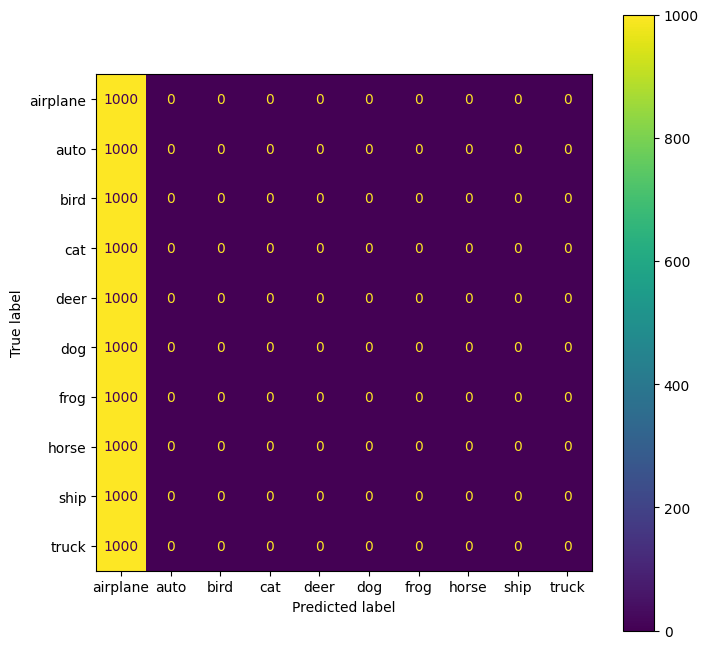

In [825]:
cauchyNN.load_model("cauchy", "49")

predictions_cauchy = []
for x in test_pca:
    pred = int(np.argmax(cauchyNN.forward(np.atleast_2d(x))))
    predictions_cauchy.append(pred)

print(sklearn.metrics.classification_report(labels_test, predictions_cauchy))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_cauchy)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Gaussian Radial Basis Function with Stochastic Gradient Descent Optimizer and K-Means Center Initialization ###

1/100, error=2.2246301717332355, train accuracy=0.23652, validation accuracy=0.2167
2/100, error=2.1862301717333055, train accuracy=0.27492, validation accuracy=0.2337
3/100, error=2.1749101717333246, train accuracy=0.28624, validation accuracy=0.2416
4/100, error=2.1676701717333358, train accuracy=0.29348, validation accuracy=0.2485
5/100, error=2.1625701717333436, train accuracy=0.29858, validation accuracy=0.2531
6/100, error=2.1582901717333507, train accuracy=0.30286, validation accuracy=0.2595
7/100, error=2.154190171733357, train accuracy=0.30696, validation accuracy=0.2642
8/100, error=2.1505101717333637, train accuracy=0.31064, validation accuracy=0.268
9/100, error=2.148190171733368, train accuracy=0.31296, validation accuracy=0.2722
10/100, error=2.1455301717333723, train accuracy=0.31562, validation accuracy=0.2754
11/100, error=2.143650171733375, train accuracy=0.3175, validation accuracy=0.279
12/100, error=2.1413301717333786, train accuracy=0.31982, validation accuracy=0.

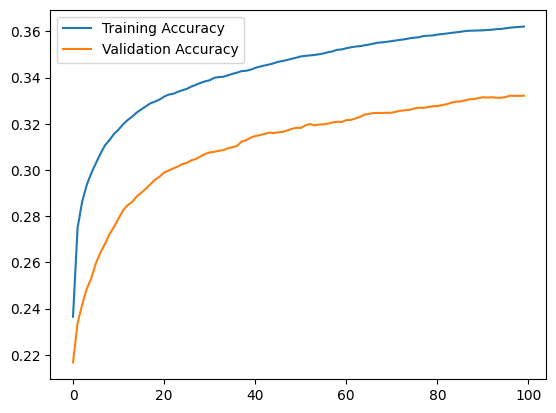

In [752]:

layers = [ 
    RBF(images_train.shape[1], num_centers),
    Dense(num_centers, 10)
]
gauss = MyRBFNN(layers, 'gauss', 'SGD', epochs*2, lr, std_dev)

gauss.train(train_pca, labels_train, test_pca, labels_test, 'kmeans', batch_size=train_size, verbose=True)

              precision    recall  f1-score   support

           0       0.36      0.67      0.47      1000
           1       0.53      0.43      0.48      1000
           2       0.41      0.04      0.07      1000
           3       0.31      0.23      0.26      1000
           4       0.29      0.45      0.35      1000
           5       0.58      0.16      0.26      1000
           6       0.59      0.17      0.27      1000
           7       0.21      0.80      0.33      1000
           8       0.78      0.14      0.23      1000
           9       0.63      0.23      0.34      1000

    accuracy                           0.33     10000
   macro avg       0.47      0.33      0.31     10000
weighted avg       0.47      0.33      0.31     10000



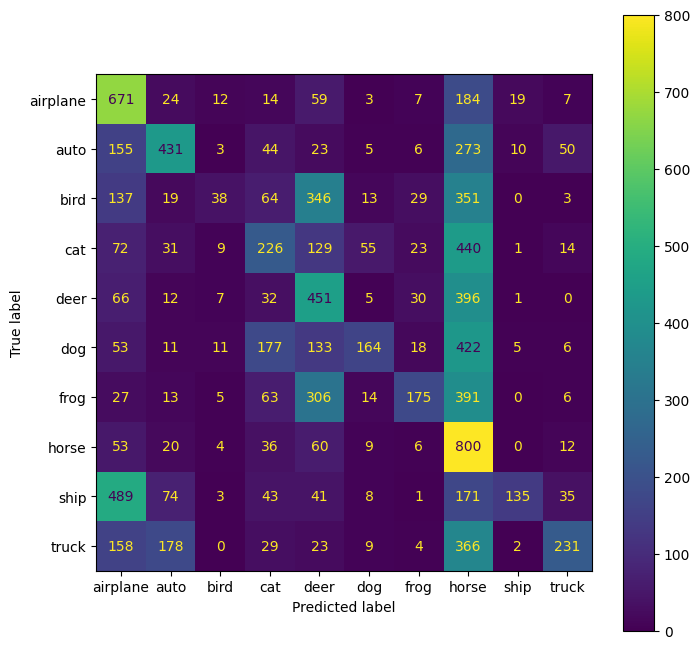

In [821]:
predictions_gauss = []
for x in test_pca:
    pred = int(np.argmax(gauss.forward(np.atleast_2d(x))))
    predictions_gauss.append(pred)

print(sklearn.metrics.classification_report(labels_test, predictions_gauss))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_gauss)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Gaussian Radial Basis Function with Adagrad Optimizer and K-Means Center Initialization ###

In [ ]:
layers = [ 
    RBF(images_train.shape[1], num_centers),
    Dense(num_centers, 10)
]
gaussAda = MyRBFNN(layers, 'gaussAda2', 'Adagrad', epochs, lr, std_dev)

gaussAda.train(train_pca, labels_train, test_pca, labels_test, 'kmeans', batch_size=train_size, verbose=True)

1/50, error=2.2182501717332483, train accuracy=0.2429, validation accuracy=0.2669
2/50, error=2.1939701717332936, train accuracy=0.26718, validation accuracy=0.2773
3/50, error=2.186290171733307, train accuracy=0.27486, validation accuracy=0.2822
4/50, error=2.1800301717333164, train accuracy=0.28112, validation accuracy=0.2852
5/50, error=2.1760701717333224, train accuracy=0.28508, validation accuracy=0.2895
6/50, error=2.173010171733326, train accuracy=0.28814, validation accuracy=0.2932
7/50, error=2.1700301717333303, train accuracy=0.29112, validation accuracy=0.2961
8/50, error=2.167010171733335, train accuracy=0.29414, validation accuracy=0.2992
9/50, error=2.1646701717333383, train accuracy=0.29648, validation accuracy=0.3023
10/50, error=2.162390171733342, train accuracy=0.29876, validation accuracy=0.3041
11/50, error=2.1605901717333453, train accuracy=0.30056, validation accuracy=0.305
12/50, error=2.158830171733348, train accuracy=0.30232, validation accuracy=0.3058
13/50, e

              precision    recall  f1-score   support

           0       0.43      0.50      0.46      1000
           1       0.37      0.33      0.35      1000
           2       0.27      0.18      0.22      1000
           3       0.24      0.05      0.08      1000
           4       0.28      0.30      0.29      1000
           5       0.33      0.36      0.34      1000
           6       0.33      0.49      0.39      1000
           7       0.30      0.26      0.28      1000
           8       0.43      0.48      0.45      1000
           9       0.36      0.48      0.41      1000

    accuracy                           0.34     10000
   macro avg       0.33      0.34      0.33     10000
weighted avg       0.33      0.34      0.33     10000



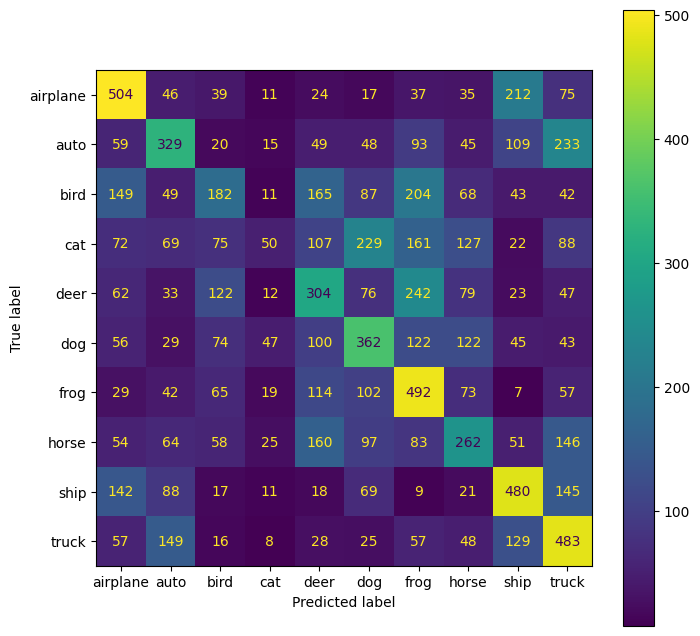

In [ ]:
predictions_gaussAda = []
for x in test_pca:
    pred = int(np.argmax(gaussAda.forward(np.atleast_2d(x))))
    predictions_gaussAda.append(pred)
print(sklearn.metrics.classification_report(labels_test, predictions_gaussAda))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_gaussAda)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Gaussian Radial Basis Function with Adagrad Optimizer and Random Center Initialization ###

1/100, error=2.209970171733261, train accuracy=0.25118, validation accuracy=0.2744
2/100, error=2.181110171733311, train accuracy=0.28004, validation accuracy=0.288
3/100, error=2.171430171733326, train accuracy=0.28972, validation accuracy=0.2962
4/100, error=2.1636301717333386, train accuracy=0.29752, validation accuracy=0.3022
5/100, error=2.1584501717333464, train accuracy=0.3027, validation accuracy=0.3079
6/100, error=2.1542901717333525, train accuracy=0.30686, validation accuracy=0.3112
7/100, error=2.1513901717333574, train accuracy=0.30976, validation accuracy=0.3133
8/100, error=2.148190171733363, train accuracy=0.31296, validation accuracy=0.3166
9/100, error=2.1450901717333686, train accuracy=0.31606, validation accuracy=0.3189
10/100, error=2.142830171733372, train accuracy=0.31832, validation accuracy=0.3205
11/100, error=2.141010171733375, train accuracy=0.32014, validation accuracy=0.3226
12/100, error=2.1393701717333773, train accuracy=0.32178, validation accuracy=0.32

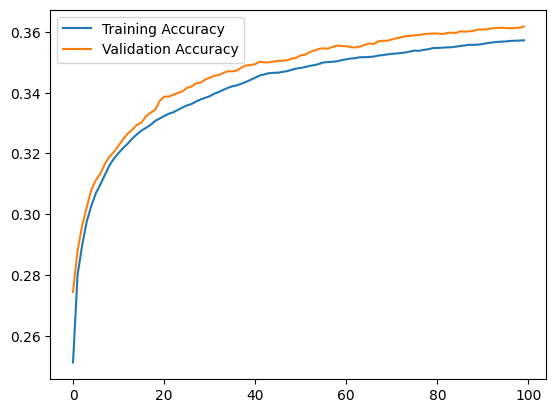

In [ ]:
layers = [ 
    RBF(images_train.shape[1], num_centers),
    Dense(num_centers, 10)
]
gaussRand = MyRBFNN(layers, 'gaussRand2', 'Adagrad', epochs, lr, std_dev)

gaussRand.train(train_pca, labels_train, test_pca, labels_test, 'random', batch_size=train_size, verbose=True)

              precision    recall  f1-score   support

           0       0.43      0.49      0.46      1000
           1       0.37      0.35      0.36      1000
           2       0.28      0.22      0.25      1000
           3       0.28      0.11      0.16      1000
           4       0.31      0.30      0.30      1000
           5       0.35      0.37      0.36      1000
           6       0.35      0.51      0.41      1000
           7       0.37      0.29      0.33      1000
           8       0.44      0.49      0.46      1000
           9       0.36      0.48      0.41      1000

    accuracy                           0.36     10000
   macro avg       0.35      0.36      0.35     10000
weighted avg       0.35      0.36      0.35     10000



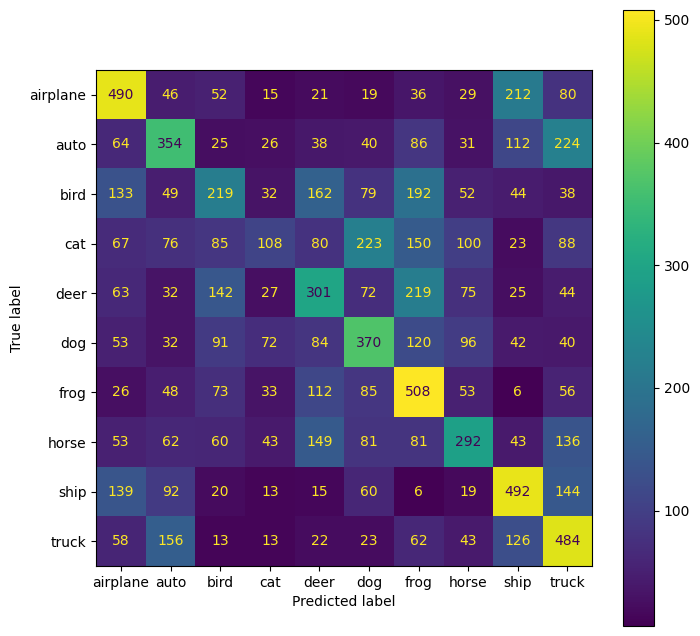

In [763]:
predictions_gaussRand = []
for x in test_pca:
    pred = int(np.argmax(gaussRand.forward(np.atleast_2d(x))))
    predictions_gaussRand.append(pred)

print(sklearn.metrics.classification_report(labels_test, predictions_gaussRand))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_gaussRand)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

## Examples of correctly and incorrectly predicted images ##

In [810]:
correct_preds_by_class = {i: [] for i in range(10)}
incorrect_preds_by_class = {i: [] for i in range(10)}

temp = list(zip(images_test, test_pca, labels_test))
np.random.shuffle(temp)
test, images, labels = zip(*temp)
test, images, labels = list(test)[0:5000], list(images)[0:5000], list(labels)[0:5000]

for i, x in enumerate(images):
    pred = int(np.argmax(gaussRand.forward(np.atleast_2d(x))))
    # _, predicted = torch.max(pre, 1) 
    
    true_label = labels[i].item()
    pred_label = pred
    
    if pred_label == true_label and len(correct_preds_by_class[true_label]) < 10:
        correct_preds_by_class[true_label].append((test[i], true_label, pred_label))
    elif pred_label != true_label and len(incorrect_preds_by_class[true_label]) < 10:
        incorrect_preds_by_class[true_label].append((test[i], true_label, pred_label))

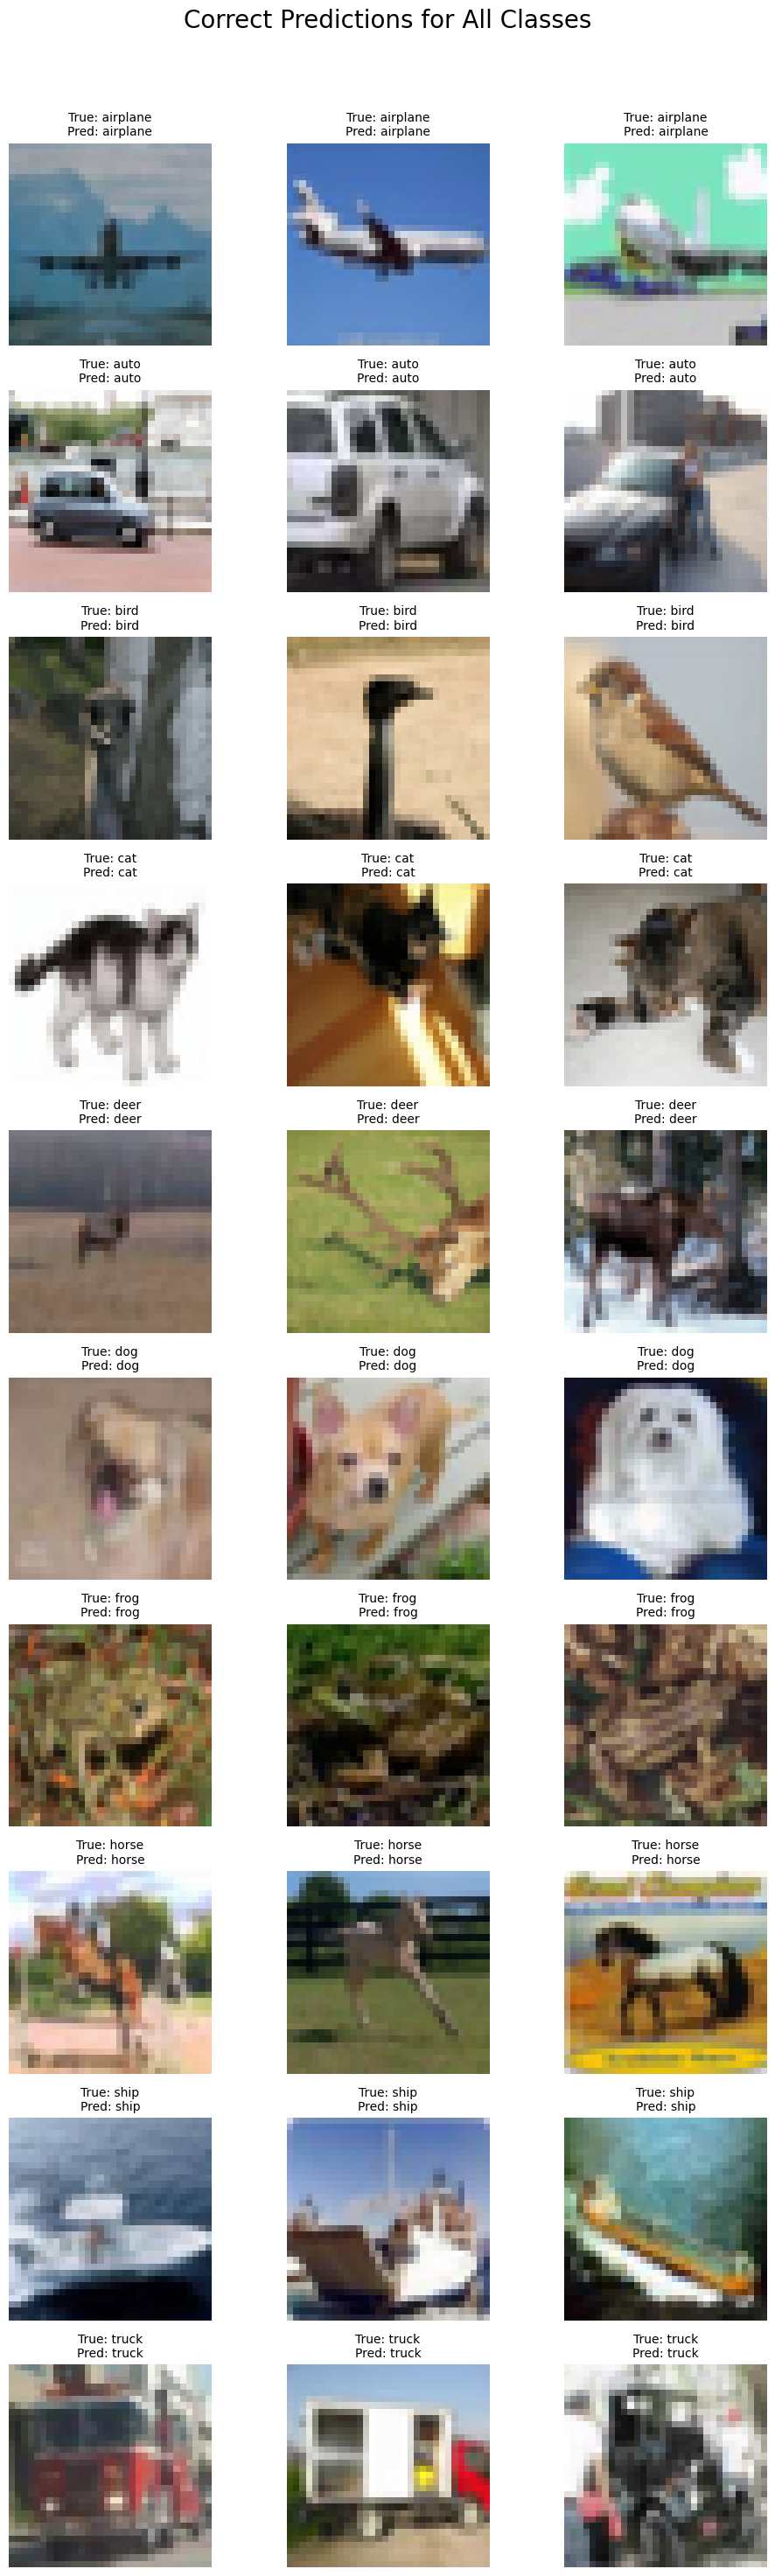

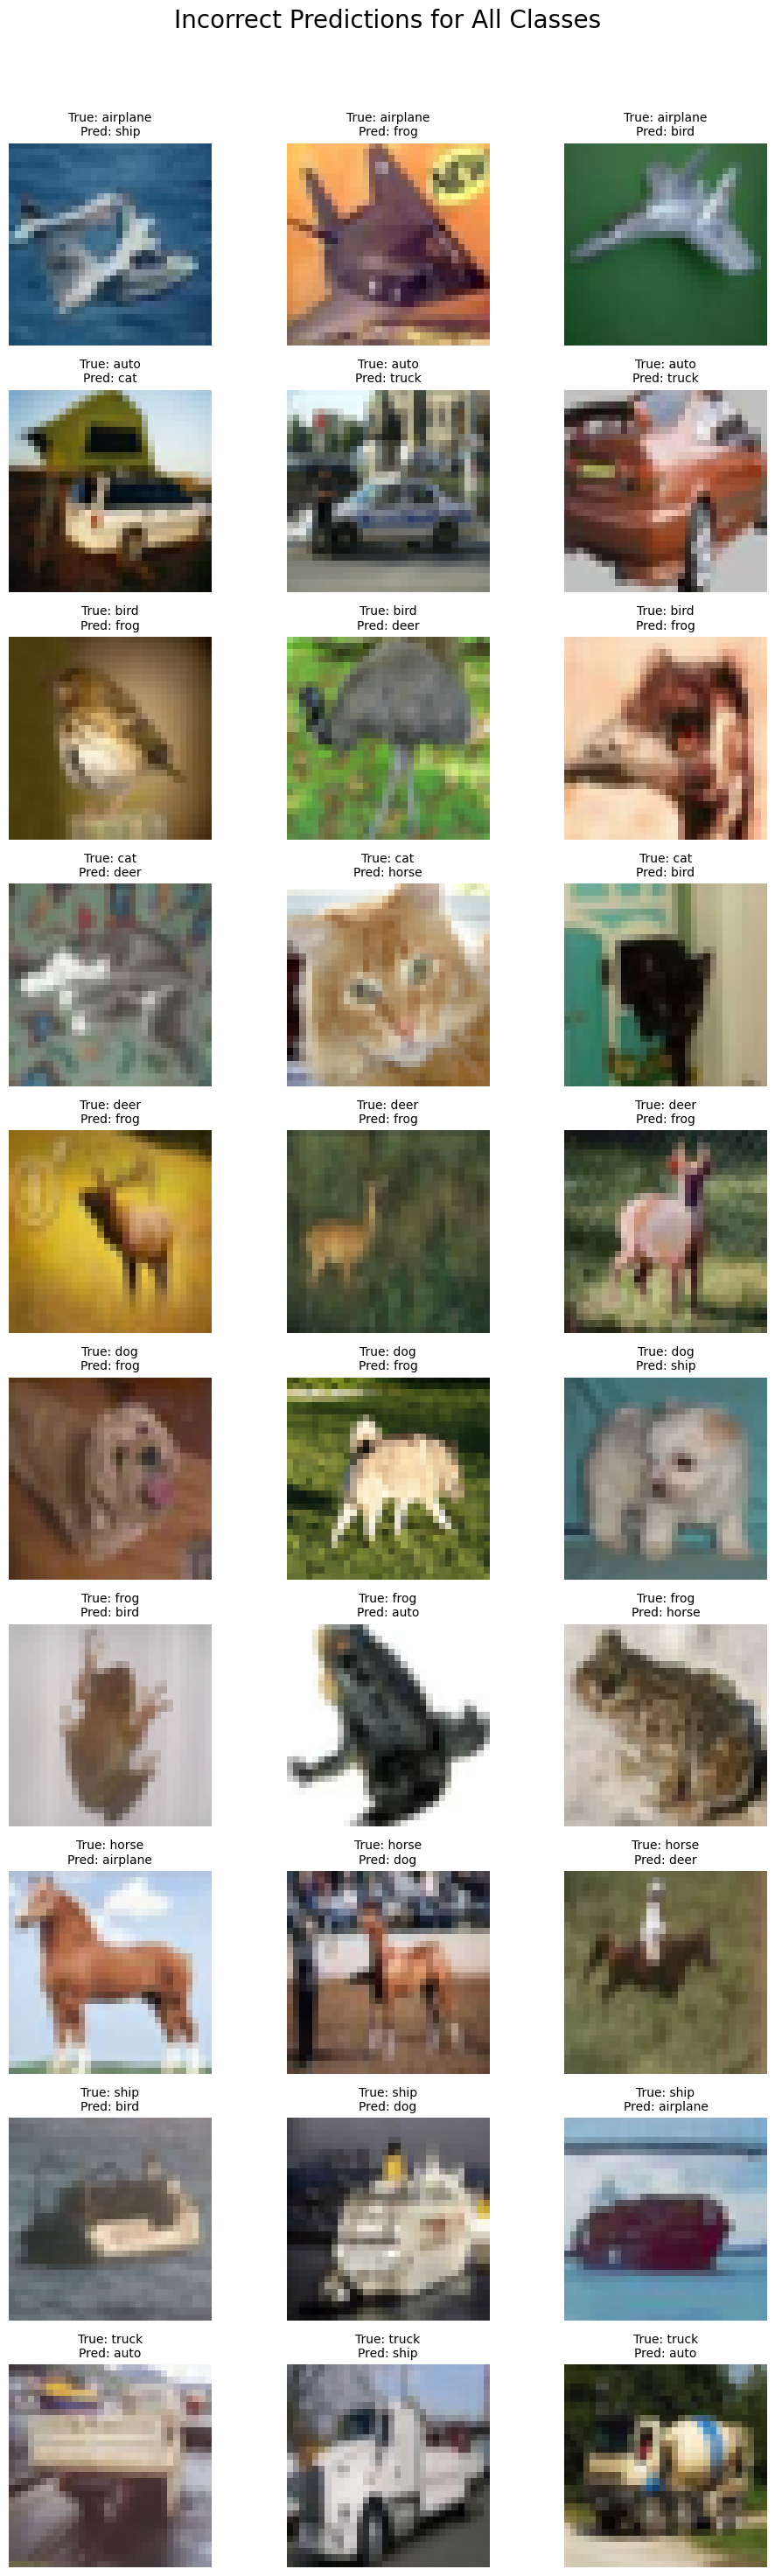

In [ ]:
def plot_images_grid(images_dict, title):
    fig, axes = plt.subplots(10, 3, figsize=(10, 10 * 3))
    fig.suptitle(title, fontsize=20)
    for class_idx in range(10):
        images_list = images_dict[class_idx]
        for idx in range(3):
            ax = axes[class_idx, idx]
            ax.axis('off')
            if idx < len(images_list):
                img, true_label, pred_label = images_list[idx]
                img = img.reshape(3,32,32).transpose(1,2,0)
                ax.imshow(((img)*std+mean).clip(0,1))
                ax.set_title(f'True: {classes[true_label]}\nPred: {classes[pred_label]}', fontsize=10)
            else:
                ax.set_visible(False) 

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_images_grid(correct_preds_by_class, 'Correct Predictions for All Classes')
plot_images_grid(incorrect_preds_by_class, 'Incorrect Predictions for All Classes')